<a href="https://colab.research.google.com/github/AtharvaDandawate/Project/blob/main/Student_marks_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

subjects = np.array([
    "Python", "NumPy", "Statistics", "SQL", "Pandas"
])
marks = np.random.randint(35, 100, (50, 5))

In [2]:
print("Number of students:", marks.shape[0])
print("Number of subjects:", marks.shape[1])
print("Shape:", marks.shape)
print("Dimensions:", marks.ndim)
print("Total marks:", marks.size)
print("Data type:", marks.dtype)
print("Memory usage:", marks.nbytes, "bytes")
print("Subjects:", subjects)
print("First five students:\n", marks[:5])

Number of students: 50
Number of subjects: 5
Shape: (50, 5)
Dimensions: 2
Total marks: 250
Data type: int64
Memory usage: 2000 bytes
Subjects: ['Python' 'NumPy' 'Statistics' 'SQL' 'Pandas']
First five students:
 [[86 49 95 55 58]
 [37 56 87 36 64]
 [72 36 98 94 55]
 [67 92 56 83 93]
 [76 94 49 96 96]]


In [3]:
print("First 10 students:\n", marks[:10, :])
print("Last subject:\n", marks[:, -1])
print("First 10 students, first 3 subjects:\n", marks[:10, :3])
print("Students 11 to 20:\n", marks[10:20, :])
print("First student's first subject mark:", marks[0, 0])

First 10 students:
 [[86 49 95 55 58]
 [37 56 87 36 64]
 [72 36 98 94 55]
 [67 92 56 83 93]
 [76 94 49 96 96]
 [81 96 85 89 98]
 [37 85 41 55 73]
 [52 38 94 48 43]
 [87 36 94 78 42]
 [81 69 70 84 38]]
Last subject:
 [58 64 55 93 96 98 73 43 42 38 88 96 74 75 43 42 75 67 78 35 49 38 70 76
 62 96 61 78 96 36 36 87 90 50 70 67 91 41 82 53 88 59 75 82 67 72 61 95
 98 80]
First 10 students, first 3 subjects:
 [[86 49 95]
 [37 56 87]
 [72 36 98]
 [67 92 56]
 [76 94 49]
 [81 96 85]
 [37 85 41]
 [52 38 94]
 [87 36 94]
 [81 69 70]]
Students 11 to 20:
 [[36 40 88 38 88]
 [97 52 78 68 96]
 [48 82 49 96 74]
 [87 58 60 94 75]
 [63 49 79 99 43]
 [35 42 97 45 42]
 [69 69 67 39 75]
 [62 41 46 68 67]
 [82 57 96 71 78]
 [69 99 81 37 35]]
First student's first subject mark: 86


In [4]:
fail_mask = marks < 40
high_mask = marks > 90

students_with_failures = np.any(fail_mask, axis=1)
failed_student_numbers = np.where(students_with_failures)[0] + 1

grade_masks = {
    "A": (marks >= 90) & (marks < 100),
    "B": (marks >= 80) & (marks < 90),
    "C": (marks >= 70) & (marks < 80),
    "D": (marks >= 60) & (marks < 70),
    "E": (marks >= 40) & (marks < 60),
    "F": marks < 40
}

grades = np.select(
    [
        marks < 40,
        marks < 60,
        marks < 70,
        marks < 80,
        marks < 90
    ],
    ["F", "E", "D", "C", "B"],
    default="A"
)

print("Failing marks:", np.sum(fail_mask))
print("Marks above 90:", np.sum(high_mask))
print("Students with failures:", failed_student_numbers)

for grade, mask in grade_masks.items():
    print(f"Grade {grade}: {np.sum(mask)} marks")

print("First five students' grades:\n", grades[:5])

Failing marks: 29
Marks above 90: 41
Students with failures: [ 2  3  7  8  9 10 11 16 17 20 21 22 27 30 31 32 35 37 39 41 49]
Grade A: 43 marks
Grade B: 37 marks
Grade C: 33 marks
Grade D: 40 marks
Grade E: 68 marks
Grade F: 29 marks
First five students' grades:
 [['B' 'E' 'A' 'E' 'E']
 ['F' 'E' 'B' 'F' 'D']
 ['C' 'F' 'A' 'A' 'E']
 ['D' 'A' 'E' 'B' 'A']
 ['C' 'A' 'E' 'A' 'A']]


In [5]:
subject_averages = np.mean(marks, axis=0)
subject_highest = np.max(marks, axis=0)
subject_lowest = np.min(marks, axis=0)

for i, subject in enumerate(subjects):
    topper_indices = np.where(marks[:, i] == subject_highest[i])[0] + 1

    print(f"\nSubject: {subject}")
    print(f"Average: {subject_averages[i]:.2f}")
    print(f"Highest mark: {subject_highest[i]}")
    print(f"Lowest mark: {subject_lowest[i]}")
    print(f"Topper(s): {topper_indices.tolist()}")


Subject: Python
Average: 65.50
Highest mark: 97
Lowest mark: 35
Topper(s): [12]

Subject: NumPy
Average: 65.74
Highest mark: 99
Lowest mark: 35
Topper(s): [20]

Subject: Statistics
Average: 68.20
Highest mark: 98
Lowest mark: 35
Topper(s): [3]

Subject: SQL
Average: 66.30
Highest mark: 99
Lowest mark: 35
Topper(s): [15]

Subject: Pandas
Average: 68.78
Highest mark: 98
Lowest mark: 35
Topper(s): [6, 49]


In [6]:
individual_pass_percentage = np.mean(marks >= 40) * 100

passed_all_subjects = np.all(marks >= 40, axis=1)
passed_any_subject = np.any(marks >= 40, axis=1)

student_pass_percentage = np.mean(passed_all_subjects) * 100

print(f"Individual-mark pass rate: {individual_pass_percentage:.2f}%")
print(f"Students passing all subjects: {student_pass_percentage:.2f}%")
print("Students passing all subjects:", np.sum(passed_all_subjects))
print("Students passing at least one subject:", np.sum(passed_any_subject))

Individual-mark pass rate: 88.40%
Students passing all subjects: 58.00%
Students passing all subjects: 29
Students passing at least one subject: 50


In [7]:
student_averages = np.mean(marks, axis=1)
ranking = np.argsort(student_averages)[::-1]

print("Top 10 students:")

for rank, index in enumerate(ranking[:10], start=1):
    print(f"Rank {rank}: Student {index + 1}, Average: {student_averages[index]:.2f}")

strongest_subject_index = np.argmax(subject_averages)
weakest_subject_index = np.argmin(subject_averages)

print("Strongest subject:", subjects[strongest_subject_index])
print("Weakest subject:", subjects[weakest_subject_index])

Top 10 students:
Rank 1: Student 6, Average: 89.80
Rank 2: Student 5, Average: 82.20
Rank 3: Student 29, Average: 79.80
Rank 4: Student 26, Average: 79.20
Rank 5: Student 12, Average: 78.20
Rank 6: Student 4, Average: 78.20
Rank 7: Student 33, Average: 77.80
Rank 8: Student 19, Average: 76.80
Rank 9: Student 22, Average: 76.40
Rank 10: Student 43, Average: 75.80
Strongest subject: Pandas
Weakest subject: Python


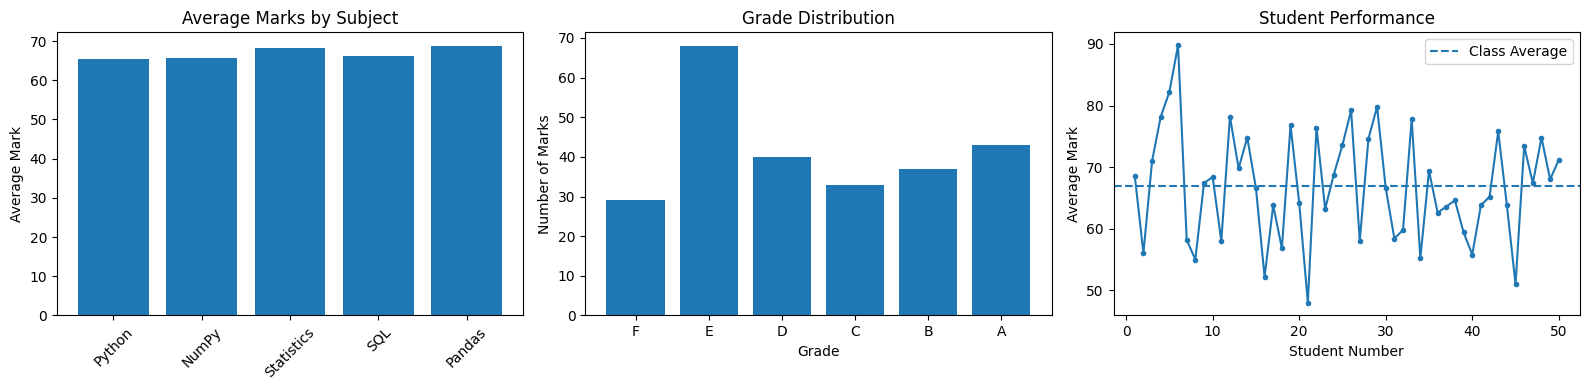

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(subjects, subject_averages)
axes[0].set_title("Average Marks by Subject")
axes[0].set_ylabel("Average Mark")
axes[0].tick_params(axis="x", rotation=45)

grade_order = ["F", "E", "D", "C", "B", "A"]
grade_counts = [np.sum(grade_masks[g]) for g in grade_order]

axes[1].bar(grade_order, grade_counts)
axes[1].set_title("Grade Distribution")
axes[1].set_xlabel("Grade")
axes[1].set_ylabel("Number of Marks")

axes[2].plot(np.arange(1, 51), student_averages, marker=".")
axes[2].axhline(student_averages.mean(), linestyle="--", label="Class Average")
axes[2].set_title("Student Performance")
axes[2].set_xlabel("Student Number")
axes[2].set_ylabel("Average Mark")
axes[2].legend()

plt.tight_layout()
plt.show()

In [9]:
print("=" * 50)
print("STUDENT MARKS ANALYZER REPORT")
print("=" * 50)

print("Total students:", marks.shape[0])
print("Total subjects:", marks.shape[1])
print("Total marks:", marks.size)
print(f"Overall average: {marks.mean():.2f}")
print(f"Individual-mark pass rate: {individual_pass_percentage:.2f}%")
print(f"Students passing every subject: {student_pass_percentage:.2f}%")
print("Students with at least one failure:", len(failed_student_numbers))

print("\nSubject averages:")

for subject, average in zip(subjects, subject_averages):
    print(f"{subject}: {average:.2f}")

print("\nTop three students:")

for rank, index in enumerate(ranking[:3], start=1):
    print(f"{rank}. Student {index + 1}: {student_averages[index]:.2f}")

print("\nStrongest subject:", subjects[strongest_subject_index])
print("Weakest subject:", subjects[weakest_subject_index])
print("=" * 50)

STUDENT MARKS ANALYZER REPORT
Total students: 50
Total subjects: 5
Total marks: 250
Overall average: 66.90
Individual-mark pass rate: 88.40%
Students passing every subject: 58.00%
Students with at least one failure: 21

Subject averages:
Python: 65.50
NumPy: 65.74
Statistics: 68.20
SQL: 66.30
Pandas: 68.78

Top three students:
1. Student 6: 89.80
2. Student 5: 82.20
3. Student 29: 79.80

Strongest subject: Pandas
Weakest subject: Python


In [10]:
assert marks.shape == (50, 5)
assert marks.ndim == 2
assert marks.size == 250
assert len(subjects) == 5
assert np.issubdtype(marks.dtype, np.integer)

assert np.all(marks >= 35)
assert np.all(marks < 100)

assert marks[:10, :].shape == (10, 5)
assert marks[:, -1].shape == (50,)
assert marks[:10, :3].shape == (10, 3)

assert fail_mask.shape == marks.shape
assert high_mask.shape == marks.shape
assert grades.shape == marks.shape

assert sum(np.sum(mask) for mask in grade_masks.values()) == marks.size

assert np.allclose(subject_averages, marks.mean(axis=0))
assert np.all(subject_highest >= subject_lowest)

assert 0 <= individual_pass_percentage <= 100
assert 0 <= student_pass_percentage <= 100

for i in range(len(subjects)):
    assert marks[:, i].max() == subject_highest[i]

boundary_marks = np.array([39, 40, 59, 60, 69, 70, 79, 80, 89, 90, 99])

boundary_grades = np.select(
    [
        boundary_marks < 40,
        boundary_marks < 60,
        boundary_marks < 70,
        boundary_marks < 80,
        boundary_marks < 90
    ],
    ["F", "E", "D", "C", "B"],
    default="A"
)

expected_grades = np.array([
    "F", "E", "E", "D", "D", "C", "C", "B", "B", "A", "A"
])

assert np.array_equal(boundary_grades, expected_grades)

print("All automated tests passed!")

All automated tests passed!
